# 03 · Churn: who won't order in the next 90 days?

**Label:** `churned_next_90d` from `marts.mart_customer_features`: no order (except one cancelled
because its payment failed) in the 90 days after the snapshot. One row per customer and monthly
snapshot, from their first revenue order on.

**Point-in-time features:** every feature in the mart reads only data from before `snapshot_at`
(#132 tests this with `assert_features_point_in_time`). From `dim_customers` only the attributes
fixed at signup are added (acquisition channel, first-touch source, city, registered or guest).
Its lifetime aggregates (`order_count`, `lifetime_net_revenue`, `last_order_at`, the device mix, the
favourite family) are computed over the whole history and would leak the future, so they're left out.

**Evaluation:** a time-based split, the honest setup for a model that will score next month's
customers: train on snapshots up to August 2025, tune on September–December 2025, test on January–
August 2026 (the last snapshot whose 90 days are fully observed). A logistic regression is the
baseline, LightGBM the candidate. Then calibration, SHAP, and a win-back list with its expected
value.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

from jassmin_ml import plots, splits
from jassmin_ml.db import read_mart
from jassmin_ml.seed import SEED, set_seeds

set_seeds()
plots.use_style()
pd.set_option("display.precision", 3)

TRAIN_END = "2025-08-01"
TEST_START = "2026-01-01"

In [2]:
raw = read_mart(
    """
    select f.customer_key, f.snapshot_date, f.is_registered, f.tenure_days, f.recency_days, f.frequency,
      f.monetary::float8 as monetary, f.avg_order_value::float8 as avg_order_value,
      f.discount_share::float8 as discount_share, f.orders_placed, f.return_rate::float8 as return_rate,
      f.unclaimed_rate::float8 as unclaimed_rate, f.sessions_30d, f.sessions_90d,
      f.days_since_last_visit, f.is_label_available, f.churned_next_90d,
      c.acquisition_channel, c.first_touch_source, c.city
    from marts.mart_customer_features f
    join marts.dim_customers c using (customer_key)
    """
)
raw["snapshot_date"] = pd.to_datetime(raw["snapshot_date"])
raw["snapshot_month"] = raw["snapshot_date"].dt.month
raw["has_visit"] = raw["days_since_last_visit"].notna()
# No logged-in visit (e.g. guests): as if the last visit were very long ago, plus the flag above.
raw["days_since_last_visit"] = raw["days_since_last_visit"].fillna(raw["tenure_days"] + 365)
for column in ["acquisition_channel", "first_touch_source", "city"]:
    raw[column] = raw[column].fillna("unknown")

NUMERIC = [
    "tenure_days", "recency_days", "frequency", "monetary", "avg_order_value", "discount_share",
    "orders_placed", "return_rate", "unclaimed_rate", "sessions_30d", "sessions_90d",
    "days_since_last_visit",
]  # fmt: skip
BOOLEAN = ["is_registered", "has_visit"]
CATEGORICAL = ["acquisition_channel", "first_touch_source", "city", "snapshot_month"]
FEATURES = NUMERIC + BOOLEAN + CATEGORICAL

labelled = raw[raw["is_label_available"]].copy()
labelled["churned"] = labelled["churned_next_90d"].astype(int)
train, validation, test = splits.time_split(labelled, "snapshot_date", TRAIN_END, TEST_START)
pd.DataFrame(
    {
        "rows": [len(train), len(validation), len(test)],
        "customers": [d["customer_key"].nunique() for d in (train, validation, test)],
        "snapshots": [f"{d['snapshot_date'].min():%Y-%m} → {d['snapshot_date'].max():%Y-%m}" for d in (train, validation, test)],
        "churn_rate": [d["churned"].mean() for d in (train, validation, test)],
    },
    index=["train", "validation", "test"],
)

,rows,customers,snapshots,churn_rate
train,23083,3101,2024-02 → 2025-08,0.840
validation,14714,4170,2025-09 → 2025-12,0.824
test,49112,7351,2026-01 → 2026-08,0.871


About 86 % of customer-months churn: most customers bought once and never come back. A model that
says "everyone churns" is already 86 % precise, so the more informative number is the precision on
the **retained** customers (PR-AUC of the minority class), reported next to the usual churn PR-AUC.

## Baseline: logistic regression

In [3]:
log_columns = ["tenure_days", "recency_days", "frequency", "monetary", "avg_order_value", "orders_placed",
               "sessions_30d", "sessions_90d", "days_since_last_visit"]
preprocess = ColumnTransformer(
    [
        ("log", make_pipeline(FunctionTransformer(np.log1p), StandardScaler()), log_columns),
        ("scale", StandardScaler(), [c for c in NUMERIC if c not in log_columns]),
        ("flags", "passthrough", BOOLEAN),
        ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=20), CATEGORICAL),
    ]
)
logit = make_pipeline(preprocess, LogisticRegression(max_iter=2000, C=1.0))


def as_model_input(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame[FEATURES].copy()
    out[BOOLEAN] = out[BOOLEAN].astype(int)
    out["snapshot_month"] = out["snapshot_month"].astype(str)
    return out


logit.fit(as_model_input(train), train["churned"])
p_logit_test = logit.predict_proba(as_model_input(test))[:, 1]

## LightGBM

Native categorical features, early stopping on the validation months, fixed seed and deterministic
training.

In [4]:
def as_lgb_input(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame[FEATURES].copy()
    out[BOOLEAN] = out[BOOLEAN].astype(int)
    for column in CATEGORICAL:
        out[column] = pd.Categorical(out[column], categories=sorted(labelled[column].unique()))
    return out


booster = lgb.LGBMClassifier(
    n_estimators=2000,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=100,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=SEED,
    deterministic=True,
    force_row_wise=True,
    n_jobs=4,
    verbose=-1,
)
booster.fit(
    as_lgb_input(train),
    train["churned"],
    eval_set=[(as_lgb_input(validation), validation["churned"])],
    eval_metric="average_precision",
    callbacks=[lgb.early_stopping(100, verbose=False)],
)
print(f"best iteration: {booster.best_iteration_}")
p_lgb_validation = booster.predict_proba(as_lgb_input(validation))[:, 1]
p_lgb_test = booster.predict_proba(as_lgb_input(test))[:, 1]

best iteration: 260


## Test results (January – August 2026)

In [5]:
y_test = test["churned"].to_numpy()


def scores(p: np.ndarray) -> dict[str, float]:
    return {
        "ROC-AUC": roc_auc_score(y_test, p),
        "PR-AUC (churn)": average_precision_score(y_test, p),
        "PR-AUC (retained)": average_precision_score(1 - y_test, 1 - p),
        "Brier": brier_score_loss(y_test, p),
    }


results = pd.DataFrame(
    {
        "base rate": {"ROC-AUC": 0.5, "PR-AUC (churn)": y_test.mean(), "PR-AUC (retained)": 1 - y_test.mean(),
                      "Brier": y_test.mean() * (1 - y_test.mean())},
        "logistic regression": scores(p_logit_test),
        "LightGBM": scores(p_lgb_test),
    }
).T
results

,ROC-AUC,PR-AUC (churn),PR-AUC (retained),Brier
base rate,0.500,0.871,0.129,0.112
logistic regression,0.786,0.957,0.405,0.094
LightGBM,0.807,0.961,0.427,0.092


LightGBM is ahead of the baseline on every metric. The gap is small, because recency and frequency
already explain most of churn and a logistic regression on log-scaled RFM captures them well. Is it
more than noise? A bootstrap over *customers* (each customer's months resampled together, since they
aren't independent), 300 resamples:

In [6]:
boot_rng = np.random.default_rng(SEED)
unique_customers, customer_index = np.unique(test["customer_key"].to_numpy(), return_inverse=True)
order = np.argsort(customer_index, kind="stable")
rows_of = np.split(order, np.cumsum(np.bincount(customer_index))[:-1])
differences = []
for _ in range(300):
    picked = np.concatenate([rows_of[i] for i in boot_rng.integers(0, len(unique_customers), len(unique_customers))])
    y = y_test[picked]
    differences.append(
        (
            average_precision_score(y, p_lgb_test[picked]) - average_precision_score(y, p_logit_test[picked]),
            average_precision_score(1 - y, 1 - p_lgb_test[picked])
            - average_precision_score(1 - y, 1 - p_logit_test[picked]),
        )
    )
differences = np.array(differences)
pd.DataFrame(
    {
        "difference": [
            results.loc["LightGBM", "PR-AUC (churn)"] - results.loc["logistic regression", "PR-AUC (churn)"],
            results.loc["LightGBM", "PR-AUC (retained)"] - results.loc["logistic regression", "PR-AUC (retained)"],
        ],
        "95% CI low": np.quantile(differences, 0.025, axis=0),
        "95% CI high": np.quantile(differences, 0.975, axis=0),
        "share of resamples > 0": (differences > 0).mean(axis=0),
    },
    index=["PR-AUC (churn): LightGBM − logistic", "PR-AUC (retained): LightGBM − logistic"],
)

,difference,95% CI low,95% CI high,share of resamples > 0
PR-AUC (churn): LightGBM − logistic,0.005,0.003,0.006,1.0
PR-AUC (retained): LightGBM − logistic,0.022,0.013,0.031,1.0


## Calibration

A churn probability is used as a probability in the win-back economics below, so it has to be
calibrated. Reliability curves on the test months, and, to check whether it's needed, an isotonic
recalibration of LightGBM fitted on the *validation* months only.

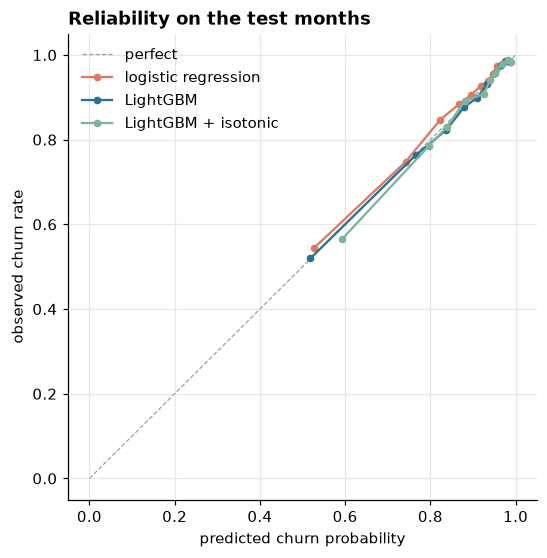

,ROC-AUC,PR-AUC (churn),PR-AUC (retained),Brier
base rate,0.500,0.871,0.129,0.112
logistic regression,0.786,0.957,0.405,0.094
LightGBM,0.807,0.961,0.427,0.092
LightGBM + isotonic,0.806,0.959,0.414,0.092


In [7]:
isotonic = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p_lgb_validation, validation["churned"])
p_lgb_calibrated = isotonic.predict(p_lgb_test)
results.loc["LightGBM + isotonic"] = scores(p_lgb_calibrated)

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], color=plots.MUTED, lw=0.8, ls="--", label="perfect")
for name, p, color in [
    ("logistic regression", p_logit_test, plots.PALETTE[1]),
    ("LightGBM", p_lgb_test, plots.ACCENT),
    ("LightGBM + isotonic", p_lgb_calibrated, plots.PALETTE[3]),
]:
    observed, predicted = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    ax.plot(predicted, observed, marker="o", ms=4, color=color, label=name)
ax.set_xlabel("predicted churn probability")
ax.set_ylabel("observed churn rate")
ax.set_title("Reliability on the test months")
ax.legend(loc="upper left")
plt.show()
results

Both models are already well calibrated (log-loss training gives calibrated probabilities when the
model isn't overfitted), and isotonic recalibration doesn't improve the Brier score on the test
months, so the raw LightGBM probabilities are used from here on.

## What drives the prediction (SHAP)

TreeSHAP values of the LightGBM model on a sample of 3,000 test rows. Positive values push towards
churn.

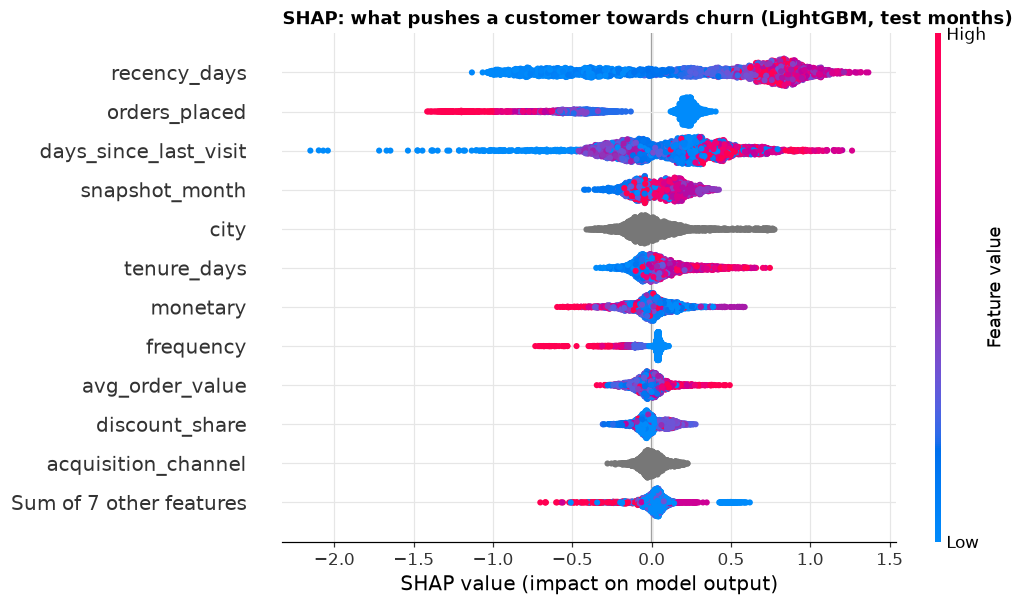

In [8]:
sample = as_lgb_input(test).sample(3000, random_state=SEED)
explainer = shap.TreeExplainer(booster)
shap_values = explainer(sample)
if shap_values.values.ndim == 3:  # some versions return one slice per class
    shap_values = shap_values[:, :, 1]

plt.figure()
shap.plots.beeswarm(shap_values, max_display=12, show=False)
fig = plt.gcf()
fig.set_size_inches(9, 6)
plt.title("SHAP: what pushes a customer towards churn (LightGBM, test months)")
plots.save_figure(fig, "03_shap_summary")
plt.show()

In [9]:
importance = (
    pd.DataFrame({"feature": sample.columns, "mean_abs_shap": np.abs(shap_values.values).mean(axis=0)})
    .sort_values("mean_abs_shap", ascending=False)
    .set_index("feature")
)
importance.head(10)

,mean_abs_shap
feature,
recency_days,0.615
orders_placed,0.364
days_since_last_visit,0.318
snapshot_month,0.131
city,0.129
tenure_days,0.118
monetary,0.101
frequency,0.085
avg_order_value,0.070


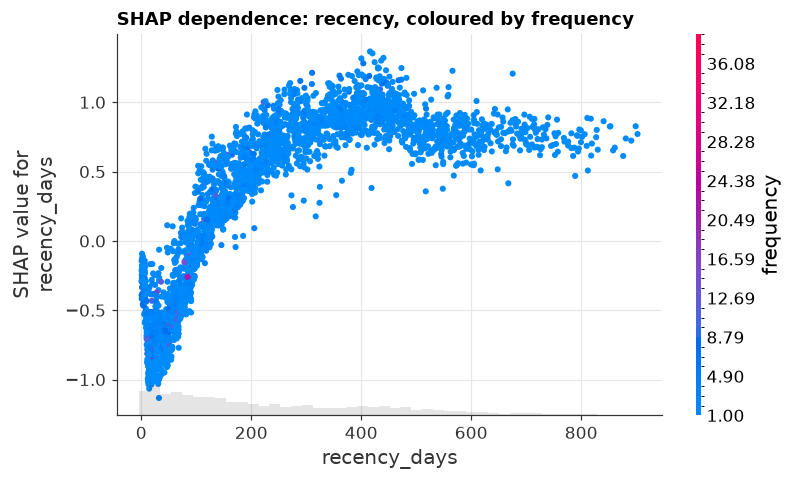

In [10]:
shap.plots.scatter(shap_values[:, "recency_days"], color=shap_values[:, "frequency"], show=False)
plt.gcf().set_size_inches(8, 4.5)
plt.title("SHAP dependence: recency, coloured by frequency")
plt.show()

- **Recency dominates**, as in every RFM analysis, but not linearly: the risk climbs steeply over
  the first ~300 days after an order and then flattens. Past that point the customer has simply gone.
- **Purchase history protects:** many orders (`orders_placed`, `frequency`) strongly lower the risk.
  Together with recency, that is the BG/NBD story from notebook 02, learned without its assumptions.
- **Browsing is a signal purchases miss:** a recent logged-in visit (`days_since_last_visit`) pulls
  the risk down. A customer who is still browsing hasn't left yet.
- **Season:** snapshots whose next 90 days include a gift season (December, February–March) churn
  less, because more customers come back to buy gifts.

**A caution about `city`.** It shows a wide SHAP spread, yet the generator gives city no effect on
churn. A 13-value category gives the trees plenty of room to fit noise. Dropping it doesn't change
the validation PR-AUC:

In [11]:
def validation_pr_auc(categorical: list[str]) -> float:
    features = NUMERIC + BOOLEAN + categorical

    def prepare(frame: pd.DataFrame) -> pd.DataFrame:
        out = frame[features].copy()
        out[BOOLEAN] = out[BOOLEAN].astype(int)
        for column in categorical:
            out[column] = pd.Categorical(out[column], categories=sorted(labelled[column].unique()))
        return out

    model = lgb.LGBMClassifier(**booster.get_params())
    model.fit(
        prepare(train),
        train["churned"],
        eval_set=[(prepare(validation), validation["churned"])],
        eval_metric="average_precision",
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    return average_precision_score(validation["churned"], model.predict_proba(prepare(validation))[:, 1])


pd.Series(
    {
        "all features": validation_pr_auc(CATEGORICAL),
        "without city": validation_pr_auc([c for c in CATEGORICAL if c != "city"]),
    },
    name="validation PR-AUC (churn)",
).to_frame()

,validation PR-AUC (churn)
all features,0.938
without city,0.938


So a high SHAP value is not evidence that a feature matters: here it is noise the model can afford.
With real data, `city` should be dropped or regularised (e.g. LightGBM's `cat_smooth`) unless a
held-out comparison like this one shows it helps.

## A win-back list for the next promo

Score every customer at the latest snapshot (1 October 2026, no label yet) with the LightGBM model,
and target a 15 %-off win-back promo. Assumptions, which only an experiment can replace:

- the promo brings back a share *u* (the uplift, 10 %) of the customers who would otherwise churn;
- each of them places one order of their usual value (their average order value);
- every redeemed promo costs 15 % of that order, including for customers who would have ordered
  anyway (1 − P(churn) of them).

Expected net gain of targeting a customer = AOV × (P(churn) × u × 0.85 − (1 − P(churn)) × 0.15).

In [12]:
latest = raw[raw["snapshot_date"] == raw["snapshot_date"].max()].copy()
latest["p_churn"] = booster.predict_proba(as_lgb_input(latest))[:, 1]
DISCOUNT = 0.15


def net_gain(frame: pd.DataFrame, uplift: float) -> pd.Series:
    p = frame["p_churn"]
    return frame["avg_order_value"] * (p * uplift * (1 - DISCOUNT) - (1 - p) * DISCOUNT)


latest["expected_net_gain"] = net_gain(latest, 0.10)
decile_size = len(latest) // 10
by_risk = latest.nlargest(decile_size, "p_churn")
by_value = latest.nlargest(decile_size, "expected_net_gain")


def summary(frame: pd.DataFrame, uplift: float) -> dict[str, float]:
    p = frame["p_churn"]
    return {
        "customers": len(frame),
        "mean P(churn)": p.mean(),
        "median recency (days)": frame["recency_days"].median(),
        "mean AOV": frame["avg_order_value"].mean(),
        "customers won back": (p * uplift).sum(),
        "revenue saved (UAH)": (p * uplift * frame["avg_order_value"] * (1 - DISCOUNT)).sum(),
        "promo cost on would-be buyers (UAH)": ((1 - p) * DISCOUNT * frame["avg_order_value"]).sum(),
        "expected net gain (UAH)": net_gain(frame, uplift).sum(),
    }


pd.DataFrame(
    {"top decile by churn risk": summary(by_risk, 0.10), "top decile by expected net gain": summary(by_value, 0.10)}
)

,top decile by churn risk,top decile by expected net gain
customers,800.000,800.000
mean P(churn),0.983,0.944
median recency (days),457.790,424.140
mean AOV,753.765,1572.249
customers won back,78.634,75.520
revenue saved (UAH),50379.081,100441.574
promo cost on would-be buyers (UAH),1547.517,11420.044
expected net gain (UAH),48831.565,89021.530


In [13]:
def best_decile(uplift: float) -> pd.DataFrame:
    return latest.assign(gain=net_gain(latest, uplift)).nlargest(decile_size, "gain")


sensitivity = pd.DataFrame(
    {
        f"uplift {u:.0%}": {
            "top decile by churn risk": net_gain(by_risk, u).sum(),
            "top decile by expected net gain": net_gain(best_decile(u), u).sum(),
        }
        for u in (0.05, 0.10, 0.20)
    }
).rename_axis("expected net gain (UAH)")
sensitivity

,uplift 5%,uplift 10%,uplift 20%
expected net gain (UAH),,,
top decile by churn risk,23642.024,48831.565,99210.646
top decile by expected net gain,39660.855,89021.530,191065.861


**Business action.** Both lists are mostly customers who haven't ordered for more than a year: this
shop's churn is high. Ranking by churn risk alone picks the surest churners, whose orders are small.
Ranking by expected net gain (risk × order value, minus the discount given away to customers who
would have ordered anyway) picks customers with about twice the order value. It nearly doubles the
expected gain at every uplift assumption, even after paying more discount to would-be buyers.

Two caveats belong next to these numbers. The uplift is assumed, not measured: someone who left
15 months ago is probably harder to win back than someone who left 4 months ago, and a constant
uplift ignores that. The promo should run as an A/B test on this list (half the list gets it), to
measure the real uplift, and later to train an uplift model that targets the *persuadable* customers
rather than the likely churners.

## Checks

In [14]:
lgb_pr, logit_pr = results.loc["LightGBM", "PR-AUC (churn)"], results.loc["logistic regression", "PR-AUC (churn)"]
print(f"PR-AUC (churn): LightGBM {lgb_pr:.4f} vs logistic {logit_pr:.4f}; "
      f"retained: {results.loc['LightGBM', 'PR-AUC (retained)']:.4f} vs {results.loc['logistic regression', 'PR-AUC (retained)']:.4f}")
assert train["snapshot_date"].max() < validation["snapshot_date"].min() <= validation["snapshot_date"].max() < test["snapshot_date"].min()
assert lgb_pr > logit_pr, "LightGBM should beat the logistic baseline on PR-AUC"
assert results.loc["LightGBM", "PR-AUC (retained)"] > results.loc["logistic regression", "PR-AUC (retained)"]
assert (differences[:, 0] > 0).mean() > 0.9, "the PR-AUC gain should hold in most bootstrap resamples"
assert (plots.FIGURES / "03_shap_summary.png").is_file()
print("03 checks passed")

PR-AUC (churn): LightGBM 0.9615 vs logistic 0.9567; retained: 0.4272 vs 0.4052
03 checks passed
